Linear Kernel Accuracy: 0.9649122807017544
Polynomial Kernel Accuracy: 0.8859649122807017
RBF Kernel Accuracy: 0.9736842105263158


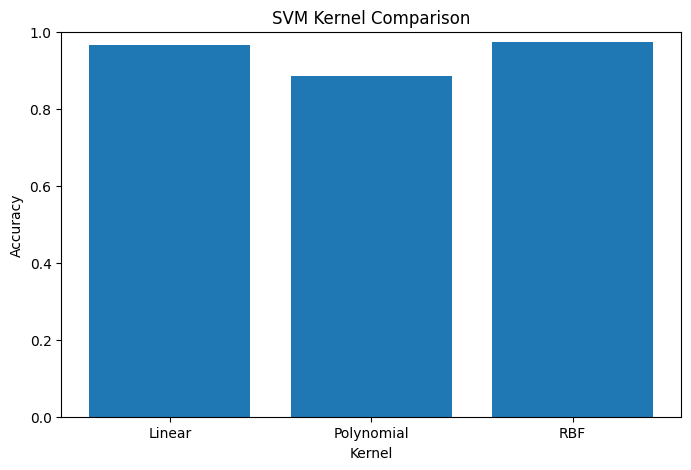


Best Parameters:
{'C': 10, 'gamma': 0.1}

Best Cross Validation Accuracy:
0.9560439560439562

Test Accuracy:
0.956140350877193

Confusion Matrix:
[[69  3]
 [ 2 40]]


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Load dataset
data = pd.read_csv("Breast Cancer Wisconsin.csv")

# Remove unnecessary columns
data = data.drop(
    ["id", "Unnamed: 32"],
    axis=1,
    errors="ignore"
)

# Convert diagnosis into numerical values
data["diagnosis"] = data["diagnosis"].map({
    "M": 1,
    "B": 0
})

# Separate input and output
X = data.drop("diagnosis", axis=1)
y = data["diagnosis"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --------------------------------------------------
# Linear Kernel
# --------------------------------------------------

linear_model = SVC(
    kernel="linear"
)

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_prediction = linear_model.predict(
    X_test_scaled
)

linear_accuracy = accuracy_score(
    y_test,
    linear_prediction
)

print("Linear Kernel Accuracy:",
      linear_accuracy)

# --------------------------------------------------
# Polynomial Kernel
# --------------------------------------------------

poly_model = SVC(
    kernel="poly"
)

poly_model.fit(
    X_train_scaled,
    y_train
)

poly_prediction = poly_model.predict(
    X_test_scaled
)

poly_accuracy = accuracy_score(
    y_test,
    poly_prediction
)

print("Polynomial Kernel Accuracy:",
      poly_accuracy)

# --------------------------------------------------
# RBF Kernel
# --------------------------------------------------

rbf_model = SVC(
    kernel="rbf"
)

rbf_model.fit(
    X_train_scaled,
    y_train
)

rbf_prediction = rbf_model.predict(
    X_test_scaled
)

rbf_accuracy = accuracy_score(
    y_test,
    rbf_prediction
)

print("RBF Kernel Accuracy:",
      rbf_accuracy)

# --------------------------------------------------
# Compare Kernels
# --------------------------------------------------

kernel_names = [
    "Linear",
    "Polynomial",
    "RBF"
]

kernel_accuracy = [
    linear_accuracy,
    poly_accuracy,
    rbf_accuracy
]

plt.figure(figsize=(8, 5))

plt.bar(
    kernel_names,
    kernel_accuracy
)

plt.xlabel("Kernel")
plt.ylabel("Accuracy")
plt.title("SVM Kernel Comparison")
plt.ylim(0, 1)
plt.show()

# --------------------------------------------------
# Hyperparameter Tuning
# --------------------------------------------------

parameter_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    SVC(kernel="rbf"),
    parameter_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(
    X_train_scaled,
    y_train
)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

# Best model
best_model = grid_search.best_estimator_

best_prediction = best_model.predict(
    X_test_scaled
)

best_accuracy = accuracy_score(
    y_test,
    best_prediction
)

print("\nTest Accuracy:")
print(best_accuracy)

# Confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        best_prediction
    )
)